# UTS Pemrograman Lanjut

Nama: T. M. Aldine Al Kautsar

NIM: 20926005

---

Diberikan kurva $$f(x) = x^2 - (N + 1)x - 1$$

garis $$y = N + 2$$

dan garis $$x = A, \quad x = B$$

Dimana $N=5$, $A$ dan $B$ adalah akar-akar dari $f(x)$

---

Kurva:

$$f(x)=x^2-6x-1$$

In [ ]:
def f(x):
  return x**2 - 6*x -1

## Program menghitung nilai $A$ dan $B$

Program harus menyediakan pilihan untuk menghitung nilai tersebut dengan menggunakan dua metode numerik.

### Metode Bisection

Dengan *initial guess* $x_1 = 5$, $x_2 = 7$

In [15]:
# Cek apakah f(a)f(b) < 0
f(5)*f(7)

-36

In [61]:
import numpy as np

x1 = 5
x2 = 7

def mid(a, b):
  return (b+a)/2

for i in range(20):
  x_mid = mid(x1, x2)
  if f(x_mid)*f(x1) > 0:
    x1 = x_mid
  else:
    x2 = x_mid

bisection = x_mid

In [64]:
print('Akar f(x) = ', bisection)

Akar f(x) =  6.16227912902832


### Metode Newton

Dengan *initial guess* $x=0$

$$x_{n+1} = x_{n} - \frac{f(x_n)}{f'(x_n)}$$

$f'(x) = 2x-6$

In [66]:
x = 0

def dydx(x):
  return 2*x - 6

for i in range(10):
  x = x - (f(x)/dydx(x))

newton = x

In [67]:
print('Akar f(x) = ', newton)

Akar f(x) =  -0.16227766016837933


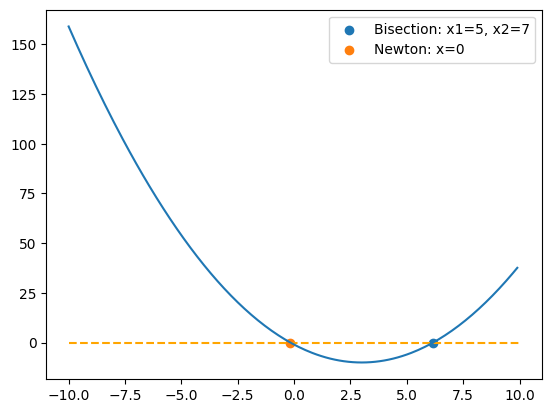

In [72]:
from matplotlib import pyplot as plt

x = np.arange(-10, 10, 0.1)
y = f(x)

plt.hlines(0, -10, 10, color='orange', linestyles='--')
plt.plot(x, y)
plt.scatter(bisection, f(bisection), label='Bisection: x1=5, x2=7')
plt.scatter(newton, f(newton), label='Newton: x=0')
plt.legend()
plt.show()

In [97]:
A = newton
B = bisection

## Program menghitung volume kolam renang
Program harus menyediakan pilihan untuk menghitung volume kolam renang dengan menggunakan tiga metode numerik.

Diketahui kedalaman dari kolam renang adalah $3$ meter.

Garis $y = 7$, $x = 6.16$, $x = -0.16$

In [101]:
h = 3 # kedalaman

# Volume kolam persegi
A_persegi = (6.16 - (-0.16)) * 7
V_persegi = A_persegi * h
print(V_persegi)

132.72


### Metode Right-Reimann Sum

$$\int_a^b f(x) dx \approx \Delta x [f(x_0) + f(x_1) + ... + f(x_{n-1})]$$

In [133]:
n = 1000
x = np.linspace(A, B, n)
dx = (B-A)/n

s = 0
for i in range(0, len(x)):
  s += f(x[i])
s *= dx

print('Volume berdasarkan RRS:', np.abs(s*h) + V_persegi)

Volume berdasarkan RRS: 259.0844885943639


### Metode Trapezoidal Rule

$$\int_a^b f(x) dx \approx \frac{\Delta x}{2} [f(x_0) + 2f(x_1) + ... + 2f(x_{n-1}) + f(x_n)]$$

In [134]:
s = 0
s += f(x[0]) + f(x[-1])
for i in range(1, len(x)-1):
  s += f(x[i]) + f(x[i+1])
s *= dx/2

print('Volume berdasarkan Trapezoidal Rule:', np.abs(s*h) + V_persegi)

Volume berdasarkan Trapezoidal Rule: 259.08410912124873


### Simpson's Rule

$$\int_a^b f(x) dx \approx \frac{\Delta x}{3} [f(x_0) + 4f(x_1) + 2f(x_2) + 4f(x_3) + 2f(x_4) + ... + 4f(x_{n-1}) + f(x_n)] $$

In [135]:
s = 0
s += f(x[0]) + f(x[-1])
for i in range(1, len(x)-1):
  if i % 2 == 0:
    s += 2 * f(x[i])
  else:
    s += 4 * f(x[i])
s *= dx/3

print('Volume berdasarkan Simpson\'s Rule:', np.abs(s*h) + V_persegi)

Volume berdasarkan Simpson's Rule: 259.08448874122047


## Program luaran diagram penampang atas kolam renang dan tabel yang memberikan panjang lahan

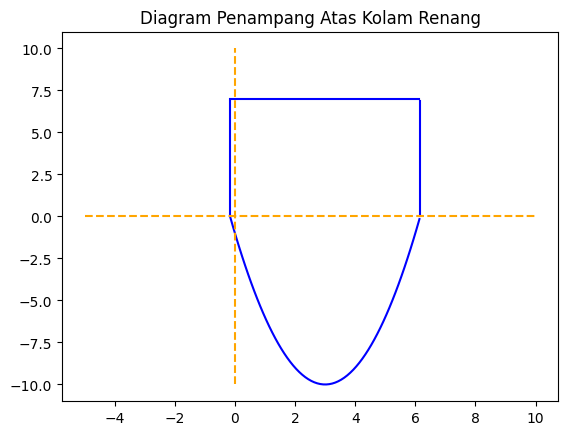

In [130]:
xn = np.arange(A, B, 0.1)
yn = 7 * np.ones(len(xn))
plt.plot(xn,yn, color='b')

yn = np.arange(0, 7, 0.1)
xn = A * np.ones(len(yn))
plt.plot(xn, yn, color='b')

yn = np.arange(0, 7, 0.1)
xn = B * np.ones(len(yn))
plt.plot(xn, yn, color='b')

xn = np.arange(A, B, 0.1)
yn = f(xn)
plt.plot(x, yn, color='b')

plt.hlines(0, -5, 10, color='orange', linestyles='--')
plt.vlines(0, -10, 10, color='orange', linestyles='--')

plt.title('Diagram Penampang Atas Kolam Renang')
plt.show()

In [159]:
xn = np.linspace(A, B, 10)
print('   x    Panjang lahan')
print('---------------------')
for n in xn:
  length = 7 + np.abs(f(n))
  print(f' {n:.2f}     {length:.4f}')

   x    Panjang lahan
---------------------
 -0.16     7.0000
 0.54     10.9506
 1.24     13.9136
 1.95     15.8889
 2.65     16.8765
 3.35     16.8765
 4.05     15.8889
 4.76     13.9136
 5.46     10.9506
 6.16     7.0000
